# 03 Baseline Model: Linear Regression

**IDX Exchange Data Science Internship, Week 4 deliverable**

**Goal.** Train a linear regression as the first model for predicting `ClosePrice`, evaluate it on the test month, and record the result. This *baseline* is the reference point for the rest of the project: the best-practices document requires that more advanced models (decision trees, random forests, gradient boosting in Weeks 5 to 7) beat it by a margin that is clearly larger than noise.

**Setup from Week 3.** The data is `data/processed/sfr_clean.csv` and the split settings are in `config/split_config.json`: models train on the 12 months before the month they predict. Two splits are used:
- **For choosing settings:** train on March 2025 to February 2026, validate on March 2026.
- **For the final result:** train on April 2025 to March 2026, test on April 2026. The test month is used once, in Section 4.

**Measures.** For each home, the percentage error is |predicted price − sale price| / sale price.
- **MdAPE**: the median percentage error over all homes; the headline measure.
- **MAPE**: the mean percentage error.
- **R²**: the share of the variation in sale prices (in dollars) that the predictions explain; 1 is perfect.
- **MAE**: the mean absolute error in dollars.

**Contents**
1. Load the data and rebuild the splits
2. The model
3. One choice on the validation month: predict price or log price
4. Final fit and the test month
5. Stability over time
6. Where the errors are
7. What the model learned
8. Saved results
9. Summary and next steps

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.linear_model import LinearRegression

ROOT = next(p for p in [Path('..'), Path('.')] if (p / 'src' / 'preprocessing.py').exists()).resolve()
sys.path.insert(0, str(ROOT))
import src.preprocessing as prep
import src.modeling as mdl

SEED = prep.set_global_seed()
print('Random seed:', SEED)

CLEAN_PATH = ROOT / 'data' / 'processed' / 'sfr_clean.csv'
CONFIG = json.loads((ROOT / 'config' / 'split_config.json').read_text())
RESULTS_DIR = ROOT / 'results'
FIG_DIR = ROOT / 'reports' / 'figures'
RESULTS_DIR.mkdir(exist_ok=True)

BLUE, ORANGE, GRAY, LIGHT_GRAY = '#2a78d6', '#eb6834', '#a3a29d', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': LIGHT_GRAY, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 9.5,
})
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=130, bbox_inches='tight')


def money(x, _=None):
    return f'${x / 1e6:.1f}M' if abs(x) >= 1e6 else f'${x / 1e3:.0f}K'


def show_metrics(m):
    # Display strings: R2 to 3 decimals, percentages to 2, MAE in whole dollars
    return {'R2': f"{m['R2']:.3f}", 'MAPE': f"{m['MAPE']:.2f}%", 'MdAPE': f"{m['MdAPE']:.2f}%",
            'MAE': f"${m['MAE']:,.0f}"}

Random seed: 42


## 1. Load the data and rebuild the splits

`make_split` recreates both splits from the cleaned data. Comparing the row counts with those saved in Week 3 confirms that the splits, and the outlier cutoffs that shape them, are exactly the Week 3 ones.

In [2]:
clean_df = prep.load_clean(CLEAN_PATH)
N_MONTHS = CONFIG['n_train_months']
TEST_MONTH = CONFIG['final']['test_month']
VALIDATION_MONTH = CONFIG['tuning']['validation_month']

train_tune, val_tune, bounds_tune = prep.make_split(clean_df, VALIDATION_MONTH, N_MONTHS)
train_final, test_final, bounds_final = prep.make_split(clean_df, TEST_MONTH, N_MONTHS)

assert len(train_final) == CONFIG['final']['train_rows'] and len(test_final) == CONFIG['final']['test_rows']
assert bounds_final == CONFIG['final']['outlier_bounds'] and bounds_tune == CONFIG['tuning']['outlier_bounds']
print(f'{len(clean_df):,} cleaned sales; training window {N_MONTHS} months')
print(f'Settings split: train {len(train_tune):,} ({train_tune.CloseMonth.min()} to {train_tune.CloseMonth.max()}), '
      f'validate {len(val_tune):,} ({VALIDATION_MONTH})')
print(f'Final split:    train {len(train_final):,} ({train_final.CloseMonth.min()} to {train_final.CloseMonth.max()}), '
      f'test {len(test_final):,} ({TEST_MONTH})')

308,862 cleaned sales; training window 12 months
Settings split: train 127,358 (2025-03 to 2026-02), validate 11,354 (2026-03)
Final split:    train 128,330 (2025-04 to 2026-03), test 12,268 (2026-04)


## 2. The model

The model is ordinary least-squares linear regression on the 65 numeric columns produced by the Week 3 preprocessor (scaled numbers, missing-value markers, county columns and the ZIP-code target encoding). `mdl.price_model` chains the preprocessor and the regression into one scikit-learn object, so that calling `fit` on training rows fits both, and calling `predict` on evaluation rows applies both with the training statistics.

The regression has no settings to tune. The one modeling choice is what it predicts: the sale price itself, or the logarithm of the sale price, converted back to dollars by exponentiating. Week 2 argued for the logarithm, because prices are strongly right-skewed and real-estate errors are naturally measured in percent. Section 3 checks this on the validation month.

## 3. One choice on the validation month: predict price or log price

Both versions are trained on the settings split and scored on March 2026.

In [3]:
choice_rows, choice_preds = {}, {}
for label, log_target in [('price', False), ('log price', True)]:
    model = mdl.price_model(LinearRegression(), log_target=log_target)
    model.fit(train_tune[prep.FEATURES], train_tune[prep.TARGET])
    pred = model.predict(val_tune[prep.FEATURES])
    choice_preds[label] = pred
    choice_rows[label] = {**show_metrics(prep.regression_metrics(val_tune[prep.TARGET], pred)),
                          'negative predictions': f'{int((pred <= 0).sum()):,}'}
choice = pd.DataFrame(choice_rows).T
choice.index.name = 'model predicts'
choice

,R2,MAPE,MdAPE,MAE,negative predictions
model predicts,,,,,
price,0.779,26.02%,18.79%,"$266,406",138
log price,0.823,15.00%,11.40%,"$199,256",0


Predicting log price is better on all four measures. The gap is largest for the percentage measures: the price version's median error is about 7 percentage points higher, because a least-squares fit in dollars is dominated by expensive homes and makes large relative errors on cheaper ones. It even predicts a negative price for some homes, which the log version cannot do. **The baseline therefore predicts log price.**

## 4. Final fit and the test month

The baseline is now trained on the final training months and evaluated once on April 2026. The training-set measures are shown next to the test measures: if the model fit its training data much better than new data, it would be *overfitting*, memorizing the training homes instead of learning general patterns.

In [4]:
baseline = mdl.price_model(LinearRegression())
baseline.fit(train_final[prep.FEATURES], train_final[prep.TARGET])
pred_train = baseline.predict(train_final[prep.FEATURES])
pred_test = baseline.predict(test_final[prep.FEATURES])

test_metrics = prep.regression_metrics(test_final[prep.TARGET], pred_test)
train_metrics = prep.regression_metrics(train_final[prep.TARGET], pred_train)
final_table = pd.DataFrame({
    f'training months ({train_final.CloseMonth.min()} to {train_final.CloseMonth.max()})': show_metrics(train_metrics),
    f'test month ({TEST_MONTH})': show_metrics(test_metrics),
}).T
final_table

,R2,MAPE,MdAPE,MAE
training months (2025-04 to 2026-03),0.835,14.79%,11.16%,"$192,268"
test month (2026-04),0.820,15.17%,11.38%,"$207,051"


In [5]:
print(f"Baseline on the test month: R2 = {test_metrics['R2']:.3f}, MdAPE = {test_metrics['MdAPE']:.2f}%, "
      f"MAPE = {test_metrics['MAPE']:.2f}%, MAE = ${test_metrics['MAE']:,.0f}")
within = 100 * np.abs(pred_test - test_final[prep.TARGET]) / test_final[prep.TARGET]
print(f'Share of test homes predicted within 5%: {(within <= 5).mean():.1%}, within 10%: {(within <= 10).mean():.1%}, '
      f'within 20%: {(within <= 20).mean():.1%}')

Baseline on the test month: R2 = 0.820, MdAPE = 11.38%, MAPE = 15.17%, MAE = $207,051
Share of test homes predicted within 5%: 23.6%, within 10%: 44.7%, within 20%: 74.5%


The training and test measures are close, so the baseline does not overfit: memorizing training homes is not what limits it. The remaining error comes from patterns in the inputs that a linear model cannot express, which more flexible models can capture, and from price differences the inputs cannot explain at all.

## 5. Stability over time

One test month can be lucky or unlucky. Following the best-practices document, the same procedure is repeated at earlier cutoffs: for each month below, train on the 12 months before it (with outlier cutoffs from those 12 months) and score that month. The three extra months are April, July and October 2025, covering spring, summer and autumn. Winter months are left out because January to March 2026 were already used in Week 3 to choose the training window.

In [6]:
BACKTEST_MONTHS = ['2025-04', '2025-07', '2025-10', TEST_MONTH]
backtest = pd.DataFrame([mdl.fit_and_score(clean_df, m, N_MONTHS, LinearRegression)[3] for m in BACKTEST_MONTHS])
backtest_view = backtest.set_index('eval_month')[['train_months', 'train_rows', 'eval_rows']].join(
    pd.DataFrame([show_metrics(r) for r in backtest.to_dict('records')], index=backtest['eval_month']))
backtest_view

,train_months,train_rows,eval_rows,R2,MAPE,MdAPE,MAE
eval_month,,,,,,,
2025-04,2024-04 to 2025-03,134510,11653,0.845,14.45%,10.83%,"$193,771"
2025-07,2024-07 to 2025-06,130834,11889,0.846,14.67%,11.00%,"$189,017"
2025-10,2024-10 to 2025-09,129199,11804,0.843,14.97%,11.16%,"$189,405"
2026-04,2025-04 to 2026-03,128330,12268,0.820,15.17%,11.38%,"$207,051"


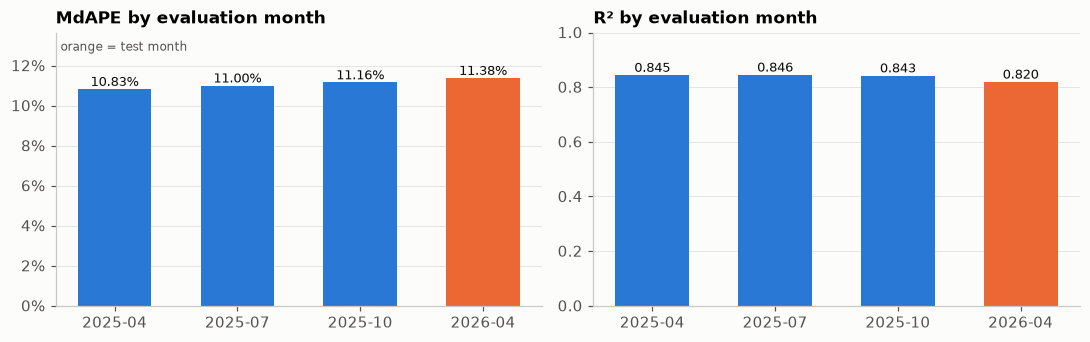

MdAPE range across the four months: 10.83% to 11.38%; R2 range: 0.820 to 0.846


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
x = range(len(backtest))
for ax, col, fmt, title in [(axes[0], 'MdAPE', lambda v: f'{v:.2f}%', 'MdAPE by evaluation month'),
                            (axes[1], 'R2', lambda v: f'{v:.3f}', 'R² by evaluation month')]:
    colors = [ORANGE if m == TEST_MONTH else BLUE for m in backtest['eval_month']]
    ax.bar(x, backtest[col], color=colors, width=0.6)
    for i, v in enumerate(backtest[col]):
        ax.text(i, v, fmt(v), ha='center', va='bottom', fontsize=8.5, color='#0b0b0b')
    ax.set_xticks(list(x), backtest['eval_month'])
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].set_ylim(0, backtest['MdAPE'].max() * 1.2)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[1].set_ylim(0, 1)
axes[0].text(0.01, 0.97, 'orange = test month', transform=axes[0].transAxes, fontsize=8, va='top', color='#52514e')
plt.tight_layout()
save_fig('03_backtest')
plt.show()

print(f"MdAPE range across the four months: {backtest['MdAPE'].min():.2f}% to {backtest['MdAPE'].max():.2f}%; "
      f"R2 range: {backtest['R2'].min():.3f} to {backtest['R2'].max():.3f}")

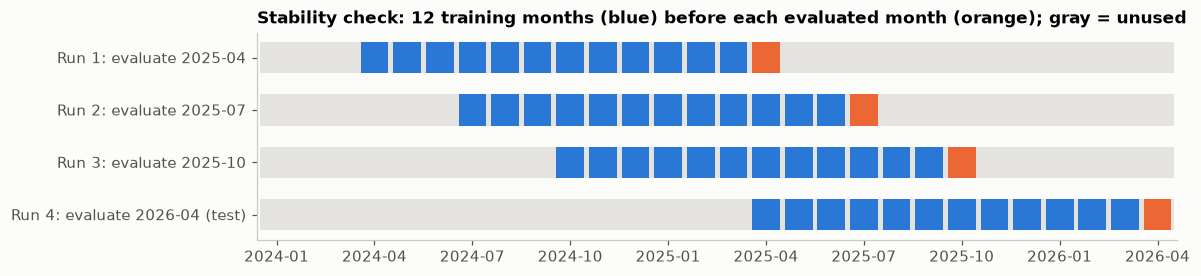

In [8]:
# Which months each of the four runs trained on (blue) and evaluated (orange)
months = sorted(clean_df['CloseMonth'].unique())
idx = {m: i for i, m in enumerate(months)}
fig, ax = plt.subplots(figsize=(11, 2.6))
for row, eval_month in enumerate(reversed(BACKTEST_MONTHS)):
    i = idx[eval_month]
    ax.barh(row, len(months), left=-0.5, height=0.6, color=LIGHT_GRAY, zorder=0)
    for m in months[i - N_MONTHS:i]:
        ax.barh(row, 0.85, left=idx[m] - 0.425, height=0.6, color=BLUE)
    ax.barh(row, 0.85, left=i - 0.425, height=0.6, color=ORANGE)
labels = [f'Run {len(BACKTEST_MONTHS) - r}: evaluate {m}' + (' (test)' if m == TEST_MONTH else '')
          for r, m in enumerate(reversed(BACKTEST_MONTHS))]
ax.set_yticks(range(len(BACKTEST_MONTHS)), labels)
ax.set_xticks(range(0, len(months), 3), [months[i] for i in range(0, len(months), 3)])
ax.set_xlim(-0.6, len(months) - 0.4)
ax.grid(False)
ax.set_title('Stability check: 12 training months (blue) before each evaluated month (orange); gray = unused')
plt.tight_layout()
save_fig('03_stability_timeline')
plt.show()

## 6. Where the errors are

A single summary number hides where a model does well or badly. The plots below use the test month.

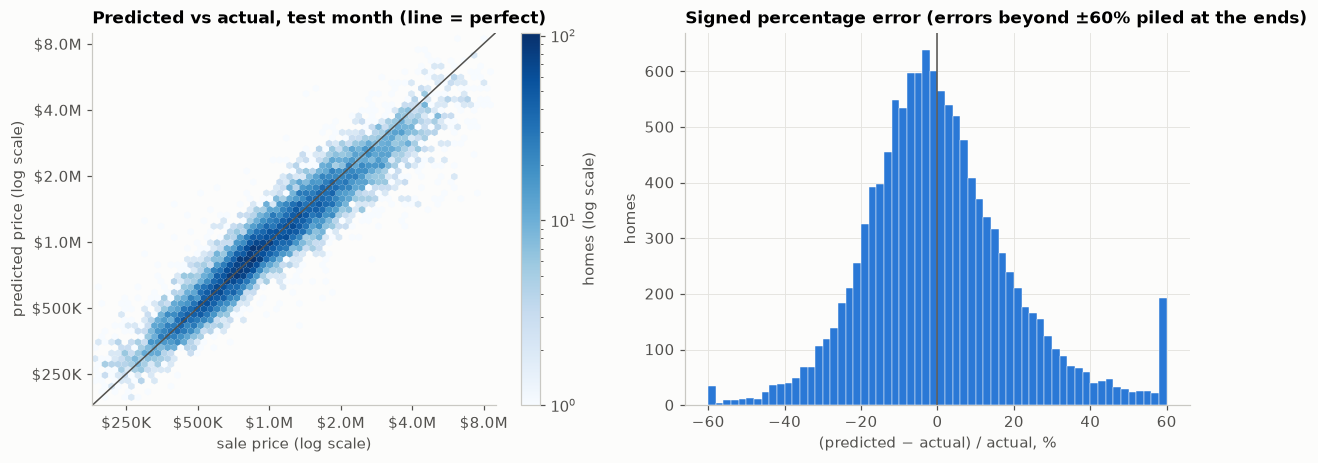

Median signed error: -1.31% (positive = predicted too high); share predicted too high: 46.8%


In [9]:
y = test_final[prep.TARGET].to_numpy()
signed = 100 * (pred_test - y) / y

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
hb = axes[0].hexbin(np.log10(y), np.log10(pred_test), gridsize=60, cmap='Blues', bins='log', mincnt=1, linewidths=0)
lims = [np.log10(1.8e5), np.log10(9e6)]
axes[0].plot(lims, lims, color='#52514e', lw=1)
ticks = [2.5e5, 5e5, 1e6, 2e6, 4e6, 8e6]
axes[0].set_xticks(np.log10(ticks), [money(t) for t in ticks])
axes[0].set_yticks(np.log10(ticks), [money(t) for t in ticks])
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('sale price (log scale)'); axes[0].set_ylabel('predicted price (log scale)')
axes[0].set_title('Predicted vs actual, test month (line = perfect)')
axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], label='homes (log scale)')

axes[1].hist(np.clip(signed, -60, 60), bins=np.arange(-60, 61, 2), color=BLUE, edgecolor='#fcfcfb', linewidth=0.3)
axes[1].axvline(0, color='#52514e', lw=1)
axes[1].set_title('Signed percentage error (errors beyond ±60% piled at the ends)')
axes[1].set_xlabel('(predicted − actual) / actual, %')
axes[1].set_ylabel('homes')
plt.tight_layout()
save_fig('03_errors')
plt.show()

print(f'Median signed error: {np.median(signed):+.2f}% (positive = predicted too high); '
      f'share predicted too high: {(signed > 0).mean():.1%}')

**By price band.** Test homes are divided into five equal-sized groups (quintiles) by their actual sale price. The *median signed error* shows whether the model systematically predicts too high (positive) or too low (negative) within a band.

In [10]:
bands = pd.qcut(y, 5, labels=[f'Q{i}' for i in range(1, 6)])
band_edges = pd.Series(y).groupby(bands, observed=True).agg(['min', 'max'])
by_band = mdl.error_by_group(y, pred_test, bands).round(2)
by_band.insert(0, 'price range', [f'{money(a)} to {money(b)}' for a, b in band_edges.to_numpy()])
by_band

,price range,homes,MdAPE,MAPE,median_signed_error
group,,,,,
Q1,$185K to $575K,2481,10.40,15.95,3.23
Q2,$575K to $800K,2481,10.05,13.19,1.18
Q3,$802K to $1.1M,2403,9.97,13.07,1.25
Q4,$1.1M to $1.7M,2449,11.74,14.86,-3.33
Q5,$1.7M to $8.6M,2454,16.03,18.76,-11.34


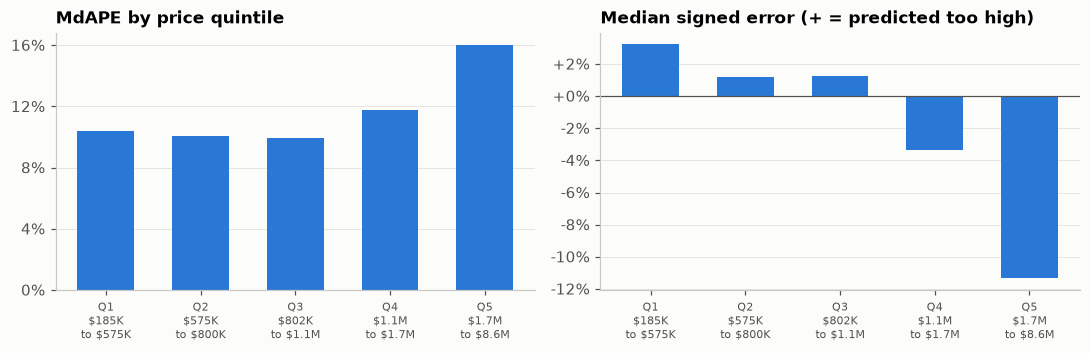

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharex=True)
# Two-line tick labels; $ is escaped because matplotlib treats it as math mode
ranges = by_band['price range'].str.replace('$', r'\$').str.replace(' to ', '\nto ')
labels = [f'{q}\n{r}' for q, r in zip(by_band.index, ranges)]
axes[0].bar(labels, by_band['MdAPE'], color=BLUE, width=0.6)
axes[0].set_title('MdAPE by price quintile')
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(4))
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}%'))
axes[1].bar(labels, by_band['median_signed_error'], color=BLUE, width=0.6)
axes[1].axhline(0, color='#52514e', lw=0.8)
axes[1].set_title('Median signed error (+ = predicted too high)')
axes[1].yaxis.set_major_locator(mtick.MultipleLocator(2))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:+.0f}%'))
for ax in axes:
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelsize=7.5)
plt.tight_layout()
save_fig('03_error_by_band')
plt.show()

**By county.** The 10 counties with the most test-month sales:

In [12]:
by_county = mdl.error_by_group(y, pred_test, test_final['CountyOrParish'])
by_county.sort_values('homes', ascending=False).head(10).round(2)

,homes,MdAPE,MAPE,median_signed_error
group,,,,
Los Angeles,3011,12.09,15.73,-1.25
Riverside,1881,11.27,15.08,0.10
San Diego,1439,11.93,15.09,-2.31
San Bernardino,1225,9.75,12.69,0.46
Orange,1166,11.21,14.21,-2.65
Alameda,591,12.78,17.04,-3.94
Contra Costa,584,10.83,13.54,-1.39
Ventura,419,11.29,15.27,-1.91
Santa Clara,392,12.61,18.23,-2.87


## 7. What the model learned

Because the model predicts log price and every numeric input is standardized, each coefficient has a direct reading: raising that input by one standard deviation, with all other inputs held fixed, multiplies the predicted price by exp(coefficient). For a 0/1 column, the same holds for switching it from 0 to 1. The chart shows this as a percentage change for the property inputs; the 36 county columns are left out for readability.

These effects hold *other inputs fixed*, which matters when inputs move together. For example, bedrooms, bathrooms and living area are strongly correlated (Week 2), so the bedroom coefficient describes adding a bedroom *without* adding living area, which in practice means smaller rooms.

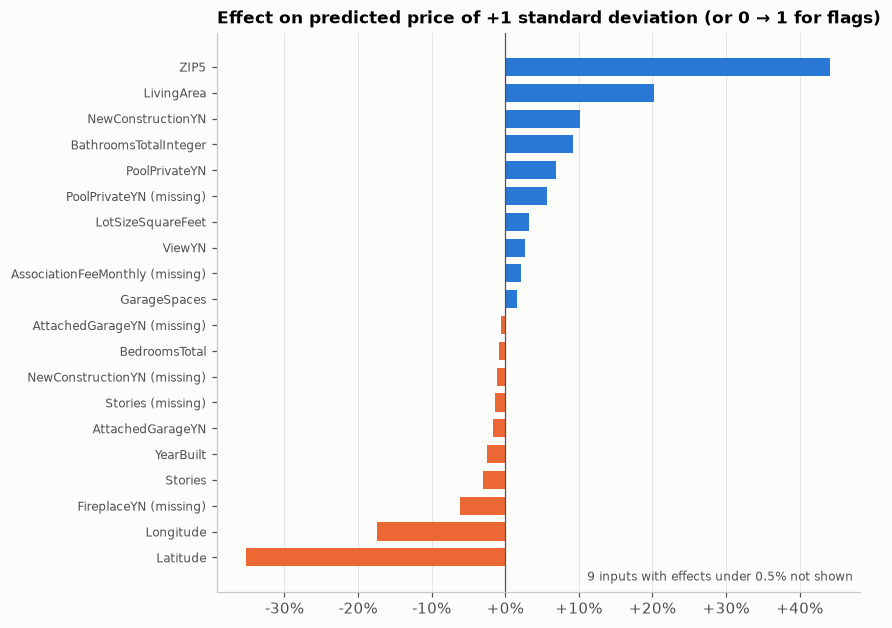

,% change in predicted price
ZIP5,44.20
Latitude,-35.20
LivingArea,20.20
Longitude,-17.40
NewConstructionYN,10.20
BathroomsTotalInteger,9.20
PoolPrivateYN,6.90
FireplaceYN (missing),-6.20


In [13]:
reg = baseline.regressor_.named_steps['model']
names = baseline.regressor_.named_steps['pre'].get_feature_names_out()
coef = pd.Series(reg.coef_, index=[n.split('__', 1)[1] for n in names])
effects = (100 * (np.exp(coef) - 1)).rename('% change in predicted price')

core = effects[[n for n in effects.index if not n.startswith('CountyOrParish')]]
core.index = [n.replace('missingindicator_', '') + ' (missing)' if n.startswith('missingindicator_')
              else n.replace('coords_imputed', 'coordinates filled in') for n in core.index]
n_small = int((core.abs() < 0.5).sum())
core = core[core.abs() >= 0.5].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.24 * len(core) + 1))
ax.barh(core.index, core.values, color=[BLUE if v >= 0 else ORANGE for v in core.values], height=0.7)
ax.axvline(0, color='#52514e', lw=0.8)
ax.set_title('Effect on predicted price of +1 standard deviation (or 0 → 1 for flags)')
ax.text(0.99, 0.02, f'{n_small} inputs with effects under 0.5% not shown', transform=ax.transAxes,
        ha='right', fontsize=8, color='#52514e')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:+.0f}%'))
ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='y', visible=False)
plt.tight_layout()
save_fig('03_coefficients')
plt.show()

core.sort_values(key=np.abs, ascending=False).head(8).round(1).to_frame()

## 8. Saved results

The metrics are written to `results/03_baseline_metrics.csv`, which holds only scores and is committed. It contains the validation result, the test result and the earlier-month results, so later notebooks can put their models next to the baseline.

In [14]:
val_row = {'evaluation': 'validation (choosing settings)', 'eval_month': VALIDATION_MONTH,
           'train_months': f'{train_tune.CloseMonth.min()} to {train_tune.CloseMonth.max()}',
           'train_rows': len(train_tune), 'eval_rows': len(val_tune),
           **prep.regression_metrics(val_tune[prep.TARGET], choice_preds['log price'])}
rows = [val_row] + [{'evaluation': 'test (final result)' if r['eval_month'] == TEST_MONTH else 'earlier month (stability)', **r}
                    for r in backtest.to_dict('records')]
results = pd.DataFrame(rows)
results.insert(0, 'model', 'Linear regression (log price)')
# The final-split row must equal the single test evaluation of Section 4
assert np.isclose(results.loc[results.eval_month == TEST_MONTH, 'MdAPE'].item(), test_metrics['MdAPE'])
results.to_csv(RESULTS_DIR / '03_baseline_metrics.csv', index=False, float_format='%.6f')
results[['evaluation', 'eval_month']].join(pd.DataFrame([show_metrics(r) for r in results.to_dict('records')]))

,evaluation,eval_month,R2,MAPE,MdAPE,MAE
0,validation (choosing settings),2026-03,0.823,15.00%,11.40%,"$199,256"
1,earlier month (stability),2025-04,0.845,14.45%,10.83%,"$193,771"
2,earlier month (stability),2025-07,0.846,14.67%,11.00%,"$189,017"
3,earlier month (stability),2025-10,0.843,14.97%,11.16%,"$189,405"
4,test (final result),2026-04,0.820,15.17%,11.38%,"$207,051"


## 9. Summary and next steps

**The recorded baseline.** Linear regression on log price, trained on April 2025 to March 2026 and evaluated once on April 2026:

| R² | MAPE | MdAPE | MAE |
|---:|---:|---:|---:|
| 0.820 | 15.17% | 11.38% | $207,051 |

Half of the test homes are predicted within 11.4% of their sale price; 23.6% are within 5%, 44.7% within 10% and 74.5% within 20%.

**How it got there**
- Predicting log price beat predicting price on the validation month on every measure (MdAPE 11.40% against 18.79%), and predicting price produced 138 negative prices.
- The baseline does not overfit: its MdAPE is 11.16% on the training months and 11.38% on the test month.
- It is stable over time: MdAPE ranges from 10.83% to 11.38% over April, July and October 2025 and April 2026. The test month is the weakest of the four, with R² 0.820 against 0.843 to 0.846 in the earlier months.

**Where it is weakest**
- The most expensive fifth of homes ($1.7M and up): MdAPE 16.0%, and the model predicts too low by a median of 11.3%. The cheapest fifth is predicted slightly too high (by a median of 3.2%). A model that adds up separate effects on log price pulls predictions toward the middle of the price range, and it cannot represent combinations that matter at the top of the market, such as a large house in an expensive ZIP code.
- Among the 10 largest counties, MdAPE ranges from 9.7% (San Bernardino) to 12.8% (Alameda), and Bay Area counties are predicted too low on balance (median signed error -3.9% in Alameda, -2.9% in Santa Clara).

**What it learned.** The ZIP-code encoding has the largest effect (+44% per standard deviation), followed by living area (+20%). Holding everything else fixed, a newly built home is predicted 10% higher; in the raw Week 2 comparison new homes were cheaper, because they are mostly built in cheaper areas, which the ZIP code now accounts for. Latitude and longitude act as broad statewide corrections once the ZIP code sets the local price level.

**Next steps (Week 5, `04_model_comparison.ipynb`)**
1. Train a decision tree and a random forest with the same preprocessor and splits, choosing their settings (tree depth, minimum leaf size, number of trees) on the March 2026 validation month.
2. Report all four measures on the test month next to this baseline, read from `results/03_baseline_metrics.csv`.
3. Judge improvements against the baseline's month-to-month variation (an MdAPE range of 0.55 percentage points over the four months above), and check whether the gains come from the top price band, where the baseline is weakest.